In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [10]:
I = cv2.imread("./StainImages/Zoernikav folio212.jpg")


In [11]:
input_path = Path("./StainImages/Zoernikav folio212.jpg")

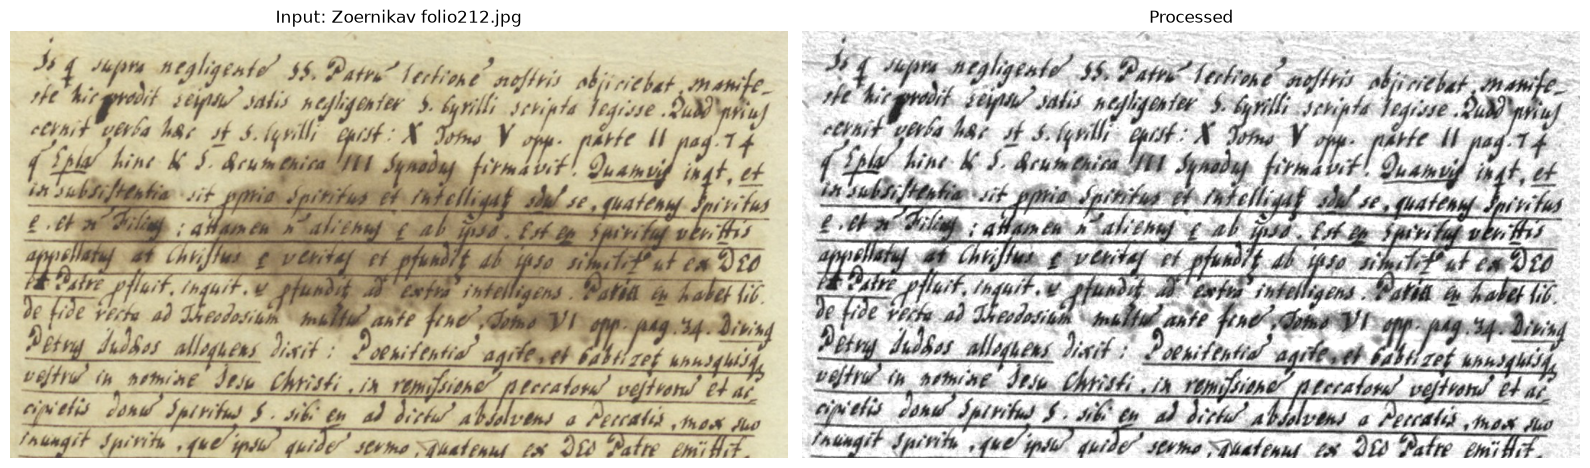

Saved: StainImages\Zoernikav folio212_processed.png


In [13]:
def remove_shadow(gray: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Dilate to erase ink, median-blur to estimate the paper, then divide it out.
    window: median window (odd), defaults to ~4% of width
    k:      dilation kernel (odd), should be wider than the thickest stroke
    """
    
        # Remove shadows / uneven staining: erase ink with dilation, estimate the paper, divide it out
    if window is None:
        window = max(3, int(gray.shape[1] * 0.04) | 1)   # ~4% of width, always odd
    k = max(3, int(gray.shape[1] * 0.006) | 1)           # dilation kernel, wider than strokes, always odd
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    dilated = cv2.dilate(gray, kernel)
    background = cv2.medianBlur(dilated, window)
    background = np.maximum(background, 1)
    norm = cv2.divide(gray, background, scale=255)

        # Remove shadows / uneven lighting: fit a smooth polynomial surface to the paper, divide it out
    # deg = 3                                               # surface flexibility (2–4 is typical)
    # h, w = gray.shape
    # scale = min(1.0, 300 / max(h, w))                     # fit on a ~300px copy for speed
    # small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA).astype(np.float32)
    # sh, sw = small.shape
    # yy, xx = np.mgrid[0:sh, 0:sw]
    # x, y, z = xx.ravel() / sw, yy.ravel() / sh, small.ravel()
    # A = np.stack([x**i * y**j for i in range(deg + 1) for j in range(deg + 1 - i)], axis=1)
    # keep = np.ones_like(z, bool)
    # for _ in range(4):                                    # iteratively drop ink (pixels well below the fit)
    #     coef, *_ = np.linalg.lstsq(A[keep], z[keep], rcond=None)
    #     resid = z - A @ coef
    #     keep = resid > -2 * resid[keep].std()
    # background = cv2.resize((A @ coef).reshape(sh, sw), (w, h), interpolation=cv2.INTER_CUBIC)
    # background = np.maximum(background, 1).astype(np.float32)
    # norm = np.clip(gray.astype(np.float32) / background * 255, 0, 255).astype(np.uint8)

    
    return np.clip(norm, 0, 255).astype(np.uint8)


def process_image(image: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Grayscale -> shadow/stain removal -> CLAHE -> sharpening."""
    if image is None or image.size == 0:
        raise ValueError("The input image is empty.")

    # Grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Remove shadows / uneven staining: estimate the paper and divide it out
    norm = remove_shadow(gray, window=window, k=k)



    # # CLAHE
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(16, 16))
    enhanced = clahe.apply(norm)

    # Sharpening (unsharp mask)
    blur = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=1.0)
    sharp = cv2.addWeighted(enhanced, 1.6, blur, -0.6, 0)

    return cv2.cvtColor(sharp, cv2.COLOR_GRAY2BGR)


output_image = process_image(I)            # or process_image(I, window=101)

# Show side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
axes[0].imshow(cv2.cvtColor(I, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"Input: {input_path.name}")
axes[1].imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)); axes[1].set_title("Processed")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Save next to the original
out_path = input_path.with_name(input_path.stem + "_processed.png")
cv2.imwrite(str(out_path), output_image)
print("Saved:", out_path)

In [4]:
cv2.imshow("Image", I)
cv2.waitKey(0)
cv2.destroyAllWindows()
